In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
import sys
import ast
import os
import matplotlib.patheffects as path_effects
sys.path.append('../')
from utils.Evaluation.calculate_metrics import calculate_scores
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as path_effects
sns.set_style(style='whitegrid')  # Better background
from collections import defaultdict, Counter
from typing import List, Tuple, Dict
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import sem
from matplotlib.cm import get_cmap
import colorsys
import numpy as np
import matplotlib.pyplot as plt
import ast

In [2]:
def extract_dfs(df):

    kg_valid_queries_df = df[df['is_KG_Valid_correct']==True].reset_index(drop=True)
    unavailable_output_df = df[df['answer']=="I couldn't find any relevant information in the database"].reset_index(drop=True)
    kg_valid_queries_with_full_schema_df = df[df['is_KG_Valid_correct_with_full_schema']==True].reset_index(drop=True)
    kg_valid_queries_with_filtered_schema_df = df[(df['is_KG_Valid_correct_with_full_schema']==False) & (df['is_KG_Valid_correct']==True)].reset_index(drop=True)

    return kg_valid_queries_df,unavailable_output_df,kg_valid_queries_with_full_schema_df,kg_valid_queries_with_filtered_schema_df

def extract_params(model_name):
    import re
    match = re.search(r'([\d.]+)[bB]', model_name)
    if match:
        return float(match.group(1))
    return 1000  # Default if no match

def count_tries(row):
    path = row['path']
    cypher_corrector_freq = path.count('cypher_corrector')
    # if 'schema_retriever' in path:
    #     # KG valid with full schema
    #     if 'output_generator' in path:
    #         count = cypher_corrector_freq - 5
    #     # Unvailable Output
    #     else:
    #         count = None
    # # KG Valid with filtered schema
    # else:
    count = cypher_corrector_freq
    return count

def remove_duplicates(row):
    unique_elements =row[:len(row) // 2]
    return unique_elements

def extract_error_types_as_lists(nested_list):
    return [[s.split(':')[0].strip() for s in sublist] for sublist in nested_list]

def extract_error_types(nested_list):
    return [s.split(':')[0] for sublist in nested_list for s in sublist]

# def calculate_dicts_with_usage(source_directory, extended=True):
#     dict_with_models = {}

#     # Decide which file to load based on workflow type
#     # if "basic_workflow" in source_directory or "extended_workflow" in source_directory:
#     #     target_file = "gpt_4o_usage.xlsx"
#     # elif "langgraph_workflow" in source_directory:
#     #     target_file = "gpt_4o_usage.xlsx"

#     for name in os.listdir(source_directory):
#         folder_path = os.path.join(source_directory, name)
#         if os.path.isdir(folder_path):
#             print(f"Entering folder: {folder_path}")
#             for file in os.listdir(folder_path):
#                 print(f"Entering file: {file}")
#                 file_path = os.path.join(folder_path, file)
#                 df_all = pd.read_excel(file_path)

#                 # SustainDataset handling
#                 if 'Sustain' in file_path:
#                     df = df_all
#                 else:
#                     df = df_all[df_all['Original_KG_Valid'] == True].reset_index(drop=True)

#                 if extended:
#                     list_columns = ['path', 'cypher_errors_history', 'cypher_errors']
#                     for col in list_columns:
#                         df[col] = df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

#                     # Extract error types from cypher_errors_history
#                     df['cypher_errors_history'] = df['cypher_errors_history'].apply(remove_duplicates)
#                     df['flattened_cypher_errors_history'] = df['cypher_errors_history'].apply(extract_error_types)
#                     df['cypher_errors_codes_history'] = df['cypher_errors_history'].apply(extract_error_types_as_lists)

#                 # Normalize model_name (remove _usage for LangGraph case)
#                 model_name = file.split('.')[0]
#                 model_name = model_name.replace('openrouter_', '').replace('_local', '')
#                 if model_name.endswith("_usage"):
#                     model_name = model_name.replace("_usage", "")

#                 dict_with_models[model_name] = df

#     return dict_with_models



def calculate_dicts_with_usage(source_directory,extended=True):
    dict_with_models={}
    for name in os.listdir(source_directory):
        folder_path = os.path.join(source_directory, name)
        if os.path.isdir(folder_path):
            # “name” is an immediate folder
            print(f"Entering folder: {folder_path}")
            # do your work here, e.g. list files inside:
            for file in os.listdir(folder_path):
                file_path = os.path.join(folder_path, file)
                if file.endswith('_usage.xlsx'):
                    print(f"Entering file: {file}")
                    df_all = pd.read_excel(file_path)
                    
                    if 'Sustain' in file_path:
                        df = df_all
                    else:
                        df = df_all[df_all['Original_KG_Valid']==True].reset_index(drop=True)
                    
                    if extended:
                        list_columns = ['path','cypher_errors_history', 'cypher_errors']
                        for col in list_columns:
                            df[col] = df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
                        
                        # Extract error types from cypher_errors_history
                        df['cypher_errors_history'] = df['cypher_errors_history'].apply(remove_duplicates)
                        df['flattened_cypher_errors_history'] = df['cypher_errors_history'].apply(extract_error_types)
                        df['cypher_errors_codes_history'] = df['cypher_errors_history'].apply(extract_error_types_as_lists)
                        # df['cypher_errors_codes_with_categories'] = df['cypher_errors_codes_history'].apply(map_errors_codes_to_categories)
                        # df['cypher_errors_with_categories'] = df['cypher_errors_history'].apply(map_errors_to_categories)
                        
                    # For rows that isKG_Valid_correct is not present, we calculate it
                    # if 'is_KG_Valid' not in df.columns:
                    #     df['is_KG_Valid'] = (
                    #                                     (df['Schema Valid'] == 1) &
                    #                                     ((df['Properties Valid'] == 1) | df['Properties Valid'].isna()) &
                    #                                     (df['Syntax Valid'] == True)
                    #                                 )
                    #     df['is_KG_Valid'] = df['is_KG_Valid'].astype(bool)   
                    model_name = file.split('.')[0]
                    model_name = model_name.replace('openrouter_', '')
                    model_name = model_name.replace('_local', '')
                    dict_with_models[model_name] = df        

    return dict_with_models

In [3]:
# # BenchmarkDataset
# models_mapping = {
#     'gpt_4o':'gpt4o', 
#     'llama3_2_3b':'Llama-3.2-3B-Instruct',
#     'finetuned_azzedde_llama3_1_8b':'Finetuned-AzzedeLlama-3.1-8b',
#     'llama3_1_8b':'Llama-3.1-8B-Instruct',
#     'gemma2_9b':'gemma-2-9b-it',
#     'finetuned_gemma2_9b': 'Finetuned-gemma-2-9b-it'
# }

# dataset = 'BenchmarkDataset2025'

# SustainDataset
models_mapping = {
    'gpt_4o':'gpt4o', 
    'llama3_2_3b':'Llama-3.2-3B-Instruct',
    'qwen2_5_7b':'Qwen2.5-7B-Instruct',
    'qwen2_5_Coder_32b':'Qwen2.5-Coder-32B-Instruct',
    'qwen2_5_72b':'Qwen2.5-72B-Instruct',
}


dataset = 'SustainDataset'

In [4]:
#Get all the dataframes with the results thate nd in _usage.xlsx
extended_dfs_dict = calculate_dicts_with_usage("./extended_workflow/Outputs_Evaluation/"+dataset,extended=True)
extended_dfs_dict = dict(sorted(extended_dfs_dict.items(), key=lambda item: extract_params(item[0])))
extended_dfs_dict.keys()
basic_dfs_dict = calculate_dicts_with_usage("./basic_workflow/Outputs_Evaluation/"+dataset,extended=False)
basic_dfs_dict = dict(sorted(basic_dfs_dict.items(), key=lambda item: extract_params(item[0])))
basic_dfs_dict.keys()
langgraph_dfs_dict = calculate_dicts_with_usage("./langgraph_workflow/Outputs_Evaluation/"+dataset,extended=False)
langgraph_dfs_dict = dict(sorted(langgraph_dfs_dict.items(), key=lambda item: extract_params(item[0])))
langgraph_dfs_dict.keys()

Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset/qwen2_5_Coder_32b
Entering file: qwen2_5_Coder_32b_usage.xlsx
Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset/qwen2_5_7b
Entering file: qwen2_5_7b_usage.xlsx
Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset/gpt_4o
Entering file: gpt_4o_usage.xlsx
Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset/llama3_2_3b
Entering file: llama3_2_3b_usage.xlsx
Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset/qwen2_5_72b
Entering file: qwen2_5_72b_usage.xlsx
Entering folder: ./basic_workflow/Outputs_Evaluation/SustainDataset/qwen2_5_Coder_32b
Entering file: qwen2_5_Coder_32b_usage.xlsx
Entering folder: ./basic_workflow/Outputs_Evaluation/SustainDataset/qwen2_5_7b
Entering file: qwen2_5_7b_usage.xlsx
Entering folder: ./basic_workflow/Outputs_Evaluation/SustainDataset/gpt_4o
Entering file: gpt_4o_usage.xlsx
Entering folder: ./basic_workflow/Outputs

dict_keys(['gpt_4o_usage'])

In [5]:
#Add number of iterations to extended dataframews
for model_name, df in extended_dfs_dict.items():
    df['Iteration'] = df.apply(count_tries, axis=1)
    df['Group'] = np.where(
    (df['is_KG_Valid_correct_with_full_schema'] == False) & (df['is_KG_Valid_correct'] == True),
    'KG Valid Queries (Filtered Schema)',
    np.where(df['is_KG_Valid_correct_with_full_schema'] == True,'KG Valid Queries (Full Schema)' , 'Unavailable Output')
    )
    df['Model'] = models_mapping[model_name.rstrip('_usage')]

for model_name, df in basic_dfs_dict.items():
    df['Model'] = models_mapping[model_name.rstrip('_usage')]

for model_name, df in langgraph_dfs_dict.items():
    df['Model'] = models_mapping[model_name.rstrip('_usage')]

In [6]:
extended_dfs_dict['gpt_4o_usage']['Group'].unique()

array(['KG Valid Queries (Filtered Schema)'], dtype=object)

In [7]:
basic_stats = []
for model_name, df in basic_dfs_dict.items():
    print(model_name)
    if 'eval_time_s' in df.columns:
        basic_stats.append({
            "Model": df['Model'].iloc[0],
            "Type": "Basic",
            "Mean Time": round(df['eval_time_s'].mean(),2),
            "Median Time": round(df['eval_time_s'].median(),2),
            "Max Time": round(df['eval_time_s'].max(),2),
            "Min Time": round(df['eval_time_s'].min(),2),
            "Std Time": round(df['eval_time_s'].std(), 2),
            "Mean Iteration Time": None , # Not applicable for basic workflow
        })
        print('added successfully')

# Collect stats for extended
extended_stats = []
for model_name, df in extended_dfs_dict.items():
    if 'eval_time_s' in df.columns:
        mean_iteration = df['Iteration'].mean() if 'Iteration' in df.columns else None
        extended_stats.append({
            "Model": df['Model'].iloc[0],
            "Type": "Extended",
            "Mean Time": round(df['eval_time_s'].mean(),2),
            "Median Time": round(df['eval_time_s'].median(),2),
            "Max Time": round(df['eval_time_s'].max(),2),
            "Min Time": round(df['eval_time_s'].min(),2),
            "Std Time": round(df['eval_time_s'].std(), 2),
            "Mean Iteration Time": mean_iteration,
        })
        print('added successfully')

langgraph_stats = []
for model_name, df in langgraph_dfs_dict.items():
    if 'eval_time_s' in df.columns:
        mean_iteration = df['Iteration'].mean() if 'Iteration' in df.columns else None
        langgraph_stats.append({
            "Model": df['Model'].iloc[0],
            "Type": "LangGraph",
            "Mean Time": round(df['eval_time_s'].mean(),2),
            "Median Time": round(df['eval_time_s'].median(),2),
            "Max Time": round(df['eval_time_s'].max(),2),
            "Min Time": round(df['eval_time_s'].min(),2),
            "Std Time": round(df['eval_time_s'].std(), 2),
            "Mean Iteration Time": None, #not applicable for langgraph workflow
        })
        print('added successfully')

# Combine into a single DataFrame
stats_df = pd.DataFrame(basic_stats + extended_stats + langgraph_stats)
stats_df['Params'] = stats_df['Model'].apply(extract_params)
stats_df = stats_df.sort_values(["Params", "Type"]).reset_index(drop=True)
display(stats_df)

llama3_2_3b_usage
added successfully
qwen2_5_7b_usage
added successfully
qwen2_5_Coder_32b_usage
added successfully
qwen2_5_72b_usage
added successfully
gpt_4o_usage
added successfully
added successfully
added successfully
added successfully
added successfully
added successfully
added successfully


,Model,Type,Mean Time,Median Time,Max Time,Min Time,Std Time,Mean Iteration Time,Params
0,Llama-3.2-3B-Instruct,Basic,2.91,1.90,31.74,0.67,4.33,NaN,3.0
1,Llama-3.2-3B-Instruct,Extended,27.16,10.59,108.41,2.32,27.96,4.326923,3.0
2,Qwen2.5-7B-Instruct,Basic,1.21,0.92,8.78,0.38,1.20,NaN,7.0
3,Qwen2.5-7B-Instruct,Extended,21.68,11.39,68.67,2.12,19.95,4.596154,7.0
4,Qwen2.5-Coder-32B-Instruct,Basic,1.32,1.24,3.35,0.60,0.62,NaN,32.0
5,Qwen2.5-Coder-32B-Instruct,Extended,11.42,7.50,85.95,2.88,13.51,0.538462,32.0
6,Qwen2.5-72B-Instruct,Basic,2.69,2.65,4.87,1.24,0.76,NaN,72.0
7,Qwen2.5-72B-Instruct,Extended,7.65,4.97,66.99,3.09,10.59,0.519231,72.0
8,gpt4o,Basic,7.15,5.72,20.63,0.68,6.16,NaN,1000.0
9,gpt4o,Extended,5.13,4.28,18.93,2.35,2.85,0.096154,1000.0


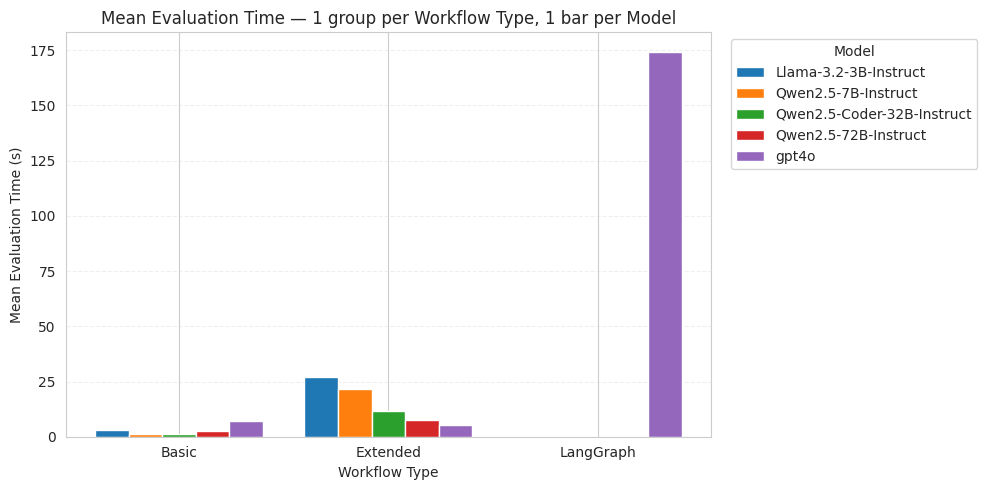

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Make sure stats_df exists and has columns: Model, Type, Mean, (optional Params)
# Example Type values expected: "Basic", "Extended", "LangGraph"

# 1) Decide the order of the groups (types) and the order of models
type_order = ["Basic", "Extended", "LangGraph"]
# keep only types that actually exist in your dataframe
type_order = [t for t in type_order if t in stats_df['Type'].unique()]

# order models by Params if available (so ordering is meaningful), otherwise preserve appearance order
if 'Params' in stats_df.columns:
    model_order = stats_df.sort_values('Params')['Model'].unique()
else:
    model_order = stats_df['Model'].unique()

n_types = len(type_order)
n_models = len(model_order)

# 2) Build a matrix of mean values for each (model, type)
means = np.full((n_models, n_types), np.nan)
for i, model in enumerate(model_order):
    for j, t in enumerate(type_order):
        val = stats_df.loc[(stats_df['Model'] == model) & (stats_df['Type'] == t), 'Mean Time']
        if not val.empty:
            means[i, j] = float(val.iloc[0])

# Replace NaNs with 0 so missing bars are shown as zero height (optional)
means_plot = np.nan_to_num(means, nan=0.0)

# 3) Plot grouped bars: each group = workflow type, each bar in group = a model
group_x = np.arange(n_types)                       # positions for the groups on the x-axis
bar_width = 0.8 / n_models                         # total group width = 0.8, split among models
# offsets so the model bars are centered inside each group
offsets = (np.arange(n_models) - (n_models - 1) / 2) * bar_width

fig, ax = plt.subplots(figsize=(10, 5))

for i, (model, offset) in enumerate(zip(model_order, offsets)):
    ax.bar(group_x + offset, means_plot[i], width=bar_width, label=str(model))

ax.set_xticks(group_x)
ax.set_xticklabels(type_order)
ax.set_xlabel("Workflow Type")
ax.set_ylabel("Mean Evaluation Time (s)")
ax.set_title("Mean Evaluation Time — 1 group per Workflow Type, 1 bar per Model")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()



In [9]:
basic_token_stats = []
for model_name, df in basic_dfs_dict.items():
    print(model_name)
    basic_stats = {"Model": df['Model'].iloc[0]}
    for col in ["total_tokens", "completion_tokens", "prompt_tokens"]:
        if col in df.columns:
            if isinstance(df[col].iloc[0], str):
                df[col] = df[col].apply(ast.literal_eval)
            # ignore -1
            token_sums = df[col].apply(lambda x: sum(int(v) for v in x if int(v) != -1))
            basic_stats["Type"] = "Basic"
            basic_stats[f"Mean {col}"] = round(token_sums.mean(), 2)
            basic_stats[f"Median {col}"] = round(token_sums.median(), 2)
            basic_stats[f"Max {col}"] = round(token_sums.max(), 2)
            basic_stats[f"Min {col}"] = round(token_sums.min(), 2)
            basic_stats[f"Std {col}"] = round(token_sums.std(), 2)
    basic_token_stats.append(basic_stats)
    print('added successfully')
basic_token_stats_df = pd.DataFrame(basic_token_stats)
print('added successfully')

extended_token_stats = []
for model_name, df in extended_dfs_dict.items():
    print(model_name)
    extended_stats = {"Model": df['Model'].iloc[0]}
    for col in ["total_tokens", "completion_tokens", "prompt_tokens"]:
        if col in df.columns:
            if isinstance(df[col].iloc[0], str):
                df[col] = df[col].apply(ast.literal_eval)
            # ignore -1
            token_sums = df[col].apply(lambda x: sum(int(v) for v in x if int(v) != -1))
            extended_stats["Type"] = "Extended"
            extended_stats[f"Mean {col}"] = round(token_sums.mean(), 2)
            extended_stats[f"Median {col}"] = round(token_sums.median(), 2)
            extended_stats[f"Max {col}"] = round(token_sums.max(), 2)
            extended_stats[f"Min {col}"] = round(token_sums.min(), 2)
            extended_stats[f"Std {col}"] = round(token_sums.std(), 2)
    extended_token_stats.append(extended_stats)
    print('added successfully')
basic_token_stats_df = pd.DataFrame(extended_token_stats)


langgraph_token_stats = []
for model_name, df in langgraph_dfs_dict.items():
    print(model_name)
    langgraph_stats = {"Model": df['Model'].iloc[0]}
    for col in ["total_tokens", "completion_tokens", "prompt_tokens"]:
        if col in df.columns:
            if isinstance(df[col].iloc[0], str):
                df[col] = df[col].apply(ast.literal_eval)
            # ignore -1
            token_sums = df[col].apply(lambda x: sum(int(v) for v in x if int(v) != -1))
            langgraph_stats["Type"] = "LangGraph"
            langgraph_stats[f"Mean {col}"] = round(token_sums.mean(), 2)
            langgraph_stats[f"Median {col}"] = round(token_sums.median(), 2)
            langgraph_stats[f"Max {col}"] = round(token_sums.max(), 2)
            langgraph_stats[f"Min {col}"] = round(token_sums.min(), 2)
            langgraph_stats[f"Std {col}"] = round(token_sums.std(), 2)
    langgraph_token_stats.append(langgraph_stats)
    print('added successfully')
basic_token_stats_df = pd.DataFrame(langgraph_token_stats)

token_stats_df = pd.DataFrame(basic_token_stats + extended_token_stats + langgraph_token_stats)
token_stats_df['Params'] = token_stats_df['Model'].apply(extract_params)
token_stats_df = token_stats_df.sort_values(["Params", "Type"]).reset_index(drop=True)
display(token_stats_df)


llama3_2_3b_usage
added successfully
qwen2_5_7b_usage
added successfully
qwen2_5_Coder_32b_usage
added successfully
qwen2_5_72b_usage
added successfully
gpt_4o_usage
added successfully
added successfully
llama3_2_3b_usage
added successfully
qwen2_5_7b_usage
added successfully
qwen2_5_Coder_32b_usage
added successfully
qwen2_5_72b_usage
added successfully
gpt_4o_usage
added successfully
gpt_4o_usage
added successfully


,Model,Type,Mean total_tokens,Median total_tokens,Max total_tokens,Min total_tokens,Std total_tokens,Mean completion_tokens,Median completion_tokens,Max completion_tokens,Min completion_tokens,Std completion_tokens,Mean prompt_tokens,Median prompt_tokens,Max prompt_tokens,Min prompt_tokens,Std prompt_tokens,Params
0,Llama-3.2-3B-Instruct,Basic,6757.15,6726.5,7693,6672,141.96,82.56,49.0,1011,11,139.64,6674.60,6673.0,6717,6661,9.80,3.0
1,Llama-3.2-3B-Instruct,Extended,24625.17,6870.0,72898,307,26522.56,425.00,132.5,2203,11,525.72,24200.17,6761.5,72021,284,26082.84,3.0
2,Qwen2.5-7B-Instruct,Basic,6863.75,6839.0,7488,6794,101.39,69.87,46.0,696,3,98.82,6793.88,6792.5,6840,6780,10.19,7.0
3,Qwen2.5-7B-Instruct,Extended,27838.60,6934.5,79029,290,29751.76,394.31,189.0,1571,9,428.91,27444.29,6875.0,77595,267,29385.67,7.0
4,Qwen2.5-Coder-32B-Instruct,Basic,6836.06,6832.0,6975,6794,35.78,42.17,38.5,135,12,27.65,6793.88,6792.5,6840,6780,10.19,32.0
5,Qwen2.5-Coder-32B-Instruct,Extended,4326.58,1522.5,53666,301,8028.47,78.44,41.0,734,13,120.48,4248.13,1495.5,52932,267,7923.44,32.0
6,Qwen2.5-72B-Instruct,Basic,6836.94,6834.5,6991,6794,36.70,43.06,40.5,151,12,28.16,6793.88,6792.5,6840,6780,10.19,72.0
7,Qwen2.5-72B-Instruct,Extended,4742.77,1505.0,55392,292,10173.93,97.88,41.0,1445,13,230.46,4644.88,1480.5,53947,267,9953.66,72.0
8,gpt4o,Basic,6672.58,6672.0,6781,6631,32.44,41.98,40.5,108,11,24.66,6630.60,6629.0,6673,6617,9.77,1000.0
9,gpt4o,Extended,2509.52,1426.5,14070,299,2530.59,45.31,41.0,123,12,29.09,2464.21,1370.5,13947,267,2513.51,1000.0


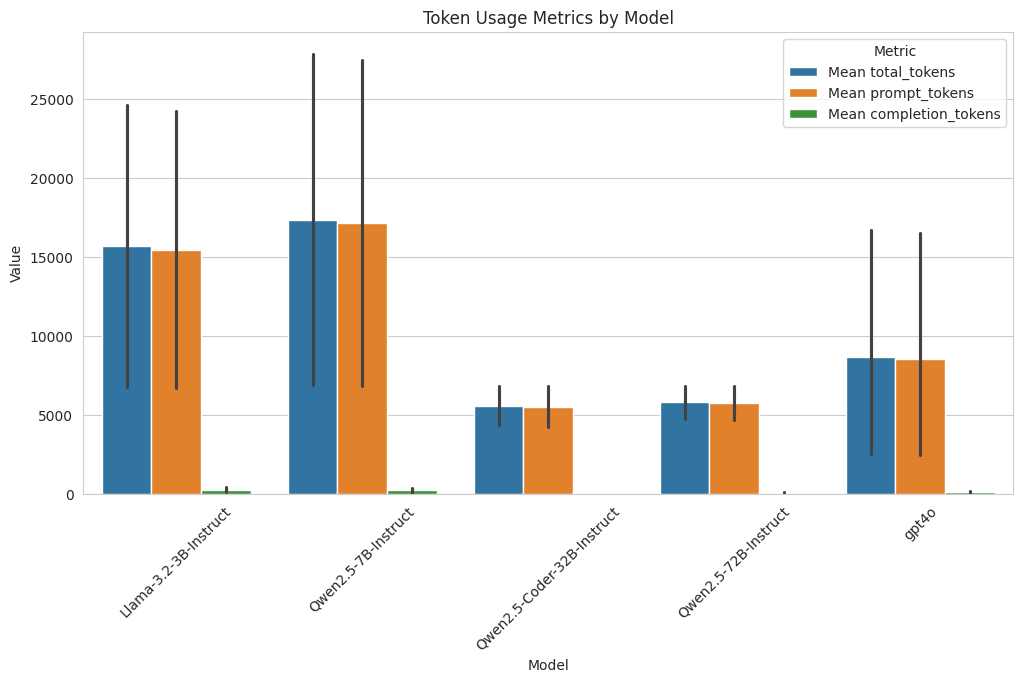

In [10]:
# token visualisation
metrics = ["Mean total_tokens", "Mean prompt_tokens", "Mean completion_tokens"]

melted = token_stats_df.melt(
    id_vars=["Model", "Type"], 
    value_vars=metrics, 
    var_name="Metric", 
    value_name="Value"
)

plt.figure(figsize=(12,6))
sns.barplot(data=melted, x="Model", y="Value", hue="Metric")
plt.xticks(rotation=45)
plt.title("Token Usage Metrics by Model")
plt.ylabel("Value")
plt.xlabel("Model")
plt.legend(title="Metric")
plt.show()


In [11]:
# Group by Model and Iteration, then aggregate eval_time_s
extended_stats_by_iter = []
for model_name, df in extended_dfs_dict.items():
    if 'eval_time_s' in df.columns and 'Iteration' in df.columns:
        grouped = df.groupby('Iteration')['eval_time_s'].agg(['mean', 'median', 'max', 'min']).reset_index()
        grouped['Model'] = df['Model'].iloc[0]
        extended_stats_by_iter.append(grouped)

# Concatenate all models' stats
stats_by_iter_df = pd.concat(extended_stats_by_iter, ignore_index=True)
stats_by_iter_df = stats_by_iter_df[['Model', 'Iteration', 'mean', 'median', 'max', 'min']]
stats_by_iter_df = stats_by_iter_df.rename(columns={
    'mean': 'Mean',
    'median': 'Median',
    'max': 'Max',
    'min': 'Min'
})
display(stats_by_iter_df)

,Model,Iteration,Mean,Median,Max,Min
0,Llama-3.2-3B-Instruct,0,4.463474,3.73280,11.0116,2.3237
1,Llama-3.2-3B-Instruct,1,8.726286,9.33810,10.1707,6.2929
2,Llama-3.2-3B-Instruct,2,10.392050,10.39205,12.5532,8.2309
3,Llama-3.2-3B-Instruct,3,15.218100,15.21810,18.7767,11.6595
4,Llama-3.2-3B-Instruct,5,20.172800,20.17280,20.1728,20.1728
5,Llama-3.2-3B-Instruct,6,36.183600,36.18360,36.1836,36.1836
6,Llama-3.2-3B-Instruct,7,39.036700,39.03670,39.0367,39.0367
7,Llama-3.2-3B-Instruct,10,58.939695,48.68940,108.4115,37.5686
8,Qwen2.5-7B-Instruct,0,3.414947,3.02700,5.3622,2.1218
9,Qwen2.5-7B-Instruct,1,8.285833,8.09605,13.1170,4.9450


In [12]:
# Select the relevant columns from both DataFrames
time_cols = ["Model", "Type", "Mean Time", "Median Time", "Std Time"]
token_cols = ["Model", "Type", "Mean total_tokens", "Median total_tokens", "Std total_tokens"]

# Merge the two DataFrames on Model + Type
merged_df = pd.merge(
    stats_df[time_cols],
    token_stats_df[token_cols],
    on=["Model", "Type"],
    how="inner"  # only keep models present in both
)

# Sort again if Params is useful
# if "Params" in stats_df.columns:
#     merged_df["Params"] = stats_df.set_index(["Model","Type"]).loc[
#         merged_df.set_index(["Model","Type"]).index
#     ]["Params"].values
#     merged_df = merged_df.sort_values(["Params", "Type"]).reset_index(drop=True)

display(merged_df)

,Model,Type,Mean Time,Median Time,Std Time,Mean total_tokens,Median total_tokens,Std total_tokens
0,Llama-3.2-3B-Instruct,Basic,2.91,1.90,4.33,6757.15,6726.5,141.96
1,Llama-3.2-3B-Instruct,Extended,27.16,10.59,27.96,24625.17,6870.0,26522.56
2,Qwen2.5-7B-Instruct,Basic,1.21,0.92,1.20,6863.75,6839.0,101.39
3,Qwen2.5-7B-Instruct,Extended,21.68,11.39,19.95,27838.60,6934.5,29751.76
4,Qwen2.5-Coder-32B-Instruct,Basic,1.32,1.24,0.62,6836.06,6832.0,35.78
5,Qwen2.5-Coder-32B-Instruct,Extended,11.42,7.50,13.51,4326.58,1522.5,8028.47
6,Qwen2.5-72B-Instruct,Basic,2.69,2.65,0.76,6836.94,6834.5,36.70
7,Qwen2.5-72B-Instruct,Extended,7.65,4.97,10.59,4742.77,1505.0,10173.93
8,gpt4o,Basic,7.15,5.72,6.16,6672.58,6672.0,32.44
9,gpt4o,Extended,5.13,4.28,2.85,2509.52,1426.5,2530.59


In [13]:
gpt4o_df = merged_df[merged_df["Model"].str.contains("gpt4o", case=False)].reset_index(drop=True)
display(gpt4o_df)

,Model,Type,Mean Time,Median Time,Std Time,Mean total_tokens,Median total_tokens,Std total_tokens
0,gpt4o,Basic,7.15,5.72,6.16,6672.58,6672.0,32.44
1,gpt4o,Extended,5.13,4.28,2.85,2509.52,1426.5,2530.59
2,gpt4o,LangGraph,174.36,61.13,195.73,16704.23,4481.0,19239.07


In [14]:
# Step 1: Collect all model names across workflows
all_models = set(list(basic_dfs_dict.keys()) + list(extended_dfs_dict.keys()) + list(langgraph_dfs_dict.keys()))

# Step 2: Initialize summary dictionary
summary_stats = {df['Model'].iloc[0]: {  # model name as key
    "Filtered Schema %": "-",
    "Mean Iterations (Filtered)": "-",
    "Full Schema %": "-",
    "Mean Iterations (Full)": "-",
    "Unavailable Output %": "-",
    "Basic Mean Total Time": "-", 
    "Basic Median Total Time": "-","Basic Std Total Time": "-",
    "Basic Mean Total Tokens": "-", 
    "Basic Median Total Tokens": "-","Basic Std Total Tokens": "-",
    "Extended Mean Total Time": "-", 
    "Extended Median Total Time": "-","Extended Std Total Time": "-",
    "Extended Mean Total Tokens": "-", 
    "Extended Median Total Tokens": "-","Extended Std Total Tokens": "-",
    "LangGraph Mean Total Time": "-", 
    "LangGraph Median Total Time": "-","LangGraph Std Total Time": "-",
    "LangGraph Mean Total Tokens": "-", 
    "LangGraph Median Total Tokens": "-","LangGraph Std Total Tokens": "-"
} for dfs_dict in [basic_dfs_dict, extended_dfs_dict, langgraph_dfs_dict] for df in dfs_dict.values()}

# Step 3: Function to fill summary for a workflow
def fill_workflow_summary(dfs_dict, workflow_type):
    for model_name, df in dfs_dict.items():
        model = df['Model'].iloc[0]
        
        # Only calculate these if 'Group' exists
        if "Group" in df.columns:
            total_questions = 52
            filtered_count = (df['Group'] == "KG Valid Queries (Filtered Schema)").sum()
            full_count = (df['Group'] == "KG Valid Queries (Full Schema)").sum()
            unavailable_count = (df['Group'] == "Unavailable Output").sum()

            filtered_iters = df.loc[df['Group'] == "KG Valid Queries (Filtered Schema)", "Iteration"]
            full_iters = df.loc[df['Group'] == "KG Valid Queries (Full Schema)", "Iteration"]

            summary_stats[model]["Filtered Schema %"] = round((filtered_count / total_questions) * 100, 2)
            summary_stats[model]["Mean Iterations (Filtered)"] = round(filtered_iters.mean(), 2) if not filtered_iters.empty else "-"
            summary_stats[model]["Full Schema %"] = round((full_count / total_questions) * 100, 2)
            summary_stats[model]["Mean Iterations (Full)"] = round(full_iters.mean(), 2) if not full_iters.empty else "-"
            summary_stats[model]["Unavailable Output %"] = round((unavailable_count / total_questions) * 100, 2)

        # Mean and Std total time
        workflow_stats = stats_df.loc[(stats_df['Model'] == model) & (stats_df['Type'] == workflow_type)]
        if not workflow_stats.empty:
            summary_stats[model][f"{workflow_type} Mean Total Time"] = workflow_stats['Mean Time'].values[0]
            summary_stats[model][f"{workflow_type} Median Total Time"] = workflow_stats['Median Time'].values[0]
            summary_stats[model][f"{workflow_type} Std Total Time"] = workflow_stats['Std Time'].values[0]

        # Mean and Std total tokens
        workflow_tokens = token_stats_df.loc[(token_stats_df['Model'] == model) & (token_stats_df['Type'] == workflow_type)]
        if not workflow_tokens.empty:
            summary_stats[model][f"{workflow_type} Mean Total Tokens"] = workflow_tokens['Mean total_tokens'].values[0]
            summary_stats[model][f"{workflow_type} Median Total Tokens"] = workflow_tokens['Median total_tokens'].values[0]
            summary_stats[model][f"{workflow_type} Std Total Tokens"] = workflow_tokens['Std total_tokens'].values[0]

# Step 4: Fill all workflows
fill_workflow_summary(basic_dfs_dict, "Basic")
fill_workflow_summary(extended_dfs_dict, "Extended")
fill_workflow_summary(langgraph_dfs_dict, "LangGraph")

# Step 5: Convert to DataFrame
summary_df = pd.DataFrame(summary_stats).reset_index(drop=False).rename(columns={"index": "Model"})
display(summary_df)


,Model,Llama-3.2-3B-Instruct,Qwen2.5-7B-Instruct,Qwen2.5-Coder-32B-Instruct,Qwen2.5-72B-Instruct,gpt4o
0,Filtered Schema %,59.62,57.69,98.08,96.15,100.0
1,Mean Iterations (Filtered),0.71,0.7,0.35,0.16,0.1
2,Full Schema %,3.85,1.92,0.0,1.92,0.0
3,Mean Iterations (Full),6.5,8.0,-,9.0,-
4,Unavailable Output %,36.54,40.38,1.92,1.92,0.0
5,Basic Mean Total Time,2.91,1.21,1.32,2.69,7.15
6,Basic Median Total Time,1.9,0.92,1.24,2.65,5.72
7,Basic Std Total Time,4.33,1.2,0.62,0.76,6.16
8,Basic Mean Total Tokens,6757.15,6863.75,6836.06,6836.94,6672.58
9,Basic Median Total Tokens,6726.5,6839.0,6832.0,6834.5,6672.0


In [15]:
df1 = summary_df.iloc[:5].reset_index(drop=True)
df2 = summary_df.iloc[5:].reset_index(drop=True)

In [16]:
display(df1)

,Model,Llama-3.2-3B-Instruct,Qwen2.5-7B-Instruct,Qwen2.5-Coder-32B-Instruct,Qwen2.5-72B-Instruct,gpt4o
0,Filtered Schema %,59.62,57.69,98.08,96.15,100.0
1,Mean Iterations (Filtered),0.71,0.7,0.35,0.16,0.1
2,Full Schema %,3.85,1.92,0.0,1.92,0.0
3,Mean Iterations (Full),6.5,8.0,-,9.0,-
4,Unavailable Output %,36.54,40.38,1.92,1.92,0.0


In [22]:
display(df2.T)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
Model,Basic Mean Total Time,Basic Median Total Time,Basic Std Total Time,Basic Mean Total Tokens,Basic Median Total Tokens,Basic Std Total Tokens,Extended Mean Total Time,Extended Median Total Time,Extended Std Total Time,Extended Mean Total Tokens,Extended Median Total Tokens,Extended Std Total Tokens,LangGraph Mean Total Time,LangGraph Median Total Time,LangGraph Std Total Time,LangGraph Mean Total Tokens,LangGraph Median Total Tokens,LangGraph Std Total Tokens
Llama-3.2-3B-Instruct,2.91,1.9,4.33,6757.15,6726.5,141.96,27.16,10.59,27.96,24625.17,6870.0,26522.56,-,-,-,-,-,-
Qwen2.5-7B-Instruct,1.21,0.92,1.2,6863.75,6839.0,101.39,21.68,11.39,19.95,27838.6,6934.5,29751.76,-,-,-,-,-,-
Qwen2.5-Coder-32B-Instruct,1.32,1.24,0.62,6836.06,6832.0,35.78,11.42,7.5,13.51,4326.58,1522.5,8028.47,-,-,-,-,-,-
Qwen2.5-72B-Instruct,2.69,2.65,0.76,6836.94,6834.5,36.7,7.65,4.97,10.59,4742.77,1505.0,10173.93,-,-,-,-,-,-
gpt4o,7.15,5.72,6.16,6672.58,6672.0,32.44,5.13,4.28,2.85,2509.52,1426.5,2530.59,174.36,61.13,195.73,16704.23,4481.0,19239.07


---------------------------------- **BENCHMARK 2025 DATASET** ----------------------------------------

In [18]:
def extract_dfs(df):
    """Safely extract different subsets if KG-related columns exist, otherwise return empty dataframes."""
    if 'is_KG_Valid_correct' in df.columns:
        kg_valid_queries_df = df[df['is_KG_Valid_correct'] == True].reset_index(drop=True)
    else:
        kg_valid_queries_df = pd.DataFrame()

    if 'answer' in df.columns:
        unavailable_output_df = df[df['answer'] == "I couldn't find any relevant information in the database"].reset_index(drop=True)
    else:
        unavailable_output_df = pd.DataFrame()

    if 'is_KG_Valid_correct_with_full_schema' in df.columns:
        kg_valid_queries_with_full_schema_df = df[df['is_KG_Valid_correct_with_full_schema'] == True].reset_index(drop=True)
        kg_valid_queries_with_filtered_schema_df = df[
            (df['is_KG_Valid_correct_with_full_schema'] == False) & 
            (df['is_KG_Valid_correct'] == True)
        ].reset_index(drop=True)
    else:
        kg_valid_queries_with_full_schema_df = pd.DataFrame()
        kg_valid_queries_with_filtered_schema_df = pd.DataFrame()

    return (
        kg_valid_queries_df,
        unavailable_output_df,
        kg_valid_queries_with_full_schema_df,
        kg_valid_queries_with_filtered_schema_df
    )


def extract_params(model_name):
    """Extract model size in billions from the name, default to 1000 if not found."""
    import re
    match = re.search(r'([\d.]+)[bB]', model_name)
    if match:
        return float(match.group(1))
    return 1000  # Default if no match


def count_tries(row):
    """Count cypher_corrector occurrences if path column exists, otherwise return 0."""
    if 'path' not in row or not isinstance(row['path'], str):
        return 0
    path = row['path']
    cypher_corrector_freq = path.count('cypher_corrector')
    return cypher_corrector_freq


def remove_duplicates(row):
    """Remove duplicate half of a list safely."""
    if isinstance(row, list):
        return row[:len(row) // 2]
    return row


def extract_error_types_as_lists(nested_list):
    """Extract error type codes from nested lists safely."""
    if not isinstance(nested_list, list):
        return []
    return [[s.split(':')[0].strip() for s in sublist if isinstance(s, str)] for sublist in nested_list]


def extract_error_types(nested_list):
    """Flatten error types from nested lists safely."""
    if not isinstance(nested_list, list):
        return []
    return [s.split(':')[0] for sublist in nested_list if isinstance(sublist, list) for s in sublist if isinstance(s, str)]


def calculate_dicts_with_usage(source_directory, extended=True):
    dict_with_models = {}
    for name in os.listdir(source_directory):
        folder_path = os.path.join(source_directory, name)
        if os.path.isdir(folder_path):
            print(f"Entering folder: {folder_path}")
            for file in os.listdir(folder_path):
                file_path = os.path.join(folder_path, file)
                if file.endswith('_usage.xlsx'):
                    print(f"Entering file: {file}")
                    df_all = pd.read_excel(file_path)

                    # If Sustain dataset → keep everything, else filter by Original_KG_Valid if present
                    if 'BenchmarkDataset2025' in file_path:
                        df = df_all
                    elif 'Original_KG_Valid' in df_all.columns:
                        df = df_all[df_all['Original_KG_Valid'] == True].reset_index(drop=True)
                    else:
                        df = df_all.reset_index(drop=True)

                    # Extended workflow only if columns exist
                    if extended:
                        list_columns = ['path', 'cypher_errors_history', 'cypher_errors']
                        for col in list_columns:
                            if col in df.columns:
                                df[col] = df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

                        if 'cypher_errors_history' in df.columns:
                            df['cypher_errors_history'] = df['cypher_errors_history'].apply(remove_duplicates)
                            df['flattened_cypher_errors_history'] = df['cypher_errors_history'].apply(extract_error_types)
                            df['cypher_errors_codes_history'] = df['cypher_errors_history'].apply(extract_error_types_as_lists)

                    # Clean model name
                    model_name = file.split('.')[0]
                    model_name = model_name.replace('openrouter_', '').replace('_local', '')
                    dict_with_models[model_name] = df        

    return dict_with_models

In [19]:
dataset = 'BenchmarkDataset2025'

In [20]:
langgraph_dfs_dict_neo4j = calculate_dicts_with_usage("./langgraph_workflow/Outputs_Evaluation/"+dataset,extended=False)
langgraph_dfs_dict_neo4j = dict(sorted(langgraph_dfs_dict_neo4j.items(), key=lambda item: extract_params(item[0])))
langgraph_dfs_dict_neo4j.keys()

Entering folder: ./langgraph_workflow/Outputs_Evaluation/BenchmarkDataset2025/gpt_4o
Entering file: gpt_4o_usage.xlsx


dict_keys(['gpt_4o_usage'])

In [21]:
model_name = "gpt_4o_usage"
df = langgraph_dfs_dict_neo4j[model_name]

time_mean = round(df["eval_time_s"].mean(), 2)
time_median = round(df["eval_time_s"].median(), 2)
time_std = round(df["eval_time_s"].std(), 2)
time_min = round(df["eval_time_s"].min(), 2)
time_max = round(df["eval_time_s"].max(), 2)

tokens_series = df["total_tokens"].dropna()

if isinstance(tokens_series.iloc[0], str) and tokens_series.iloc[0].startswith("["):
    tokens_series = tokens_series.apply(
        lambda x: sum(int(v) for v in ast.literal_eval(x) if v != -1) if pd.notna(x) else np.nan
    )
elif isinstance(tokens_series.iloc[0], list):
    tokens_series = tokens_series.apply(
        lambda x: sum(int(v) for v in x if v != -1) if isinstance(x, list) else np.nan
    )
else:
    tokens_series = pd.to_numeric(tokens_series, errors="coerce")

tokens_mean = round(tokens_series.mean(), 2)
tokens_median = round(tokens_series.median(), 2)
tokens_std = round(tokens_series.std(), 2)

summary_dict_neo4j = {
    "Model": [
        "LangGraph Mean Total Time", "LangGraph Median Total Time", "Std Total Time", "Min Time", "Max Time",
        "LangGraph Mean Total Tokens", "LangGraph Median Total Tokens", "LangGraph Std Total Tokens"
    ],
    model_name.rstrip("_usage"): [
        time_mean, time_median, time_std, time_min, time_max,
        tokens_mean, tokens_median, tokens_std
    ]
}

summary_df_neo4j = pd.DataFrame(summary_dict_neo4j)
print("LangGraph workflow")
display(summary_df_neo4j)

LangGraph workflow


,Model,gpt_4o
0,LangGraph Mean Total Time,30.67
1,LangGraph Median Total Time,18.44
2,Std Total Time,38.21
3,Min Time,9.04
4,Max Time,428.22
5,LangGraph Mean Total Tokens,2007.11
6,LangGraph Median Total Tokens,1173.00
7,LangGraph Std Total Tokens,3367.68
